C:\Users\MOI\AppData\Local\Temp\ipykernel_19184\4037627449.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  heatmap_img = Image.fromarray(final_array, mode="RGB")
C:\Users\MOI\AppData\Local\Temp\ipykernel_19184\4037627449.py:96: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(selected_array, mode="RGB")
C:\Users\MOI\AppData\Local\Temp\ipykernel_19184\4037627449.py:108: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(soft_array, mode="RGB")


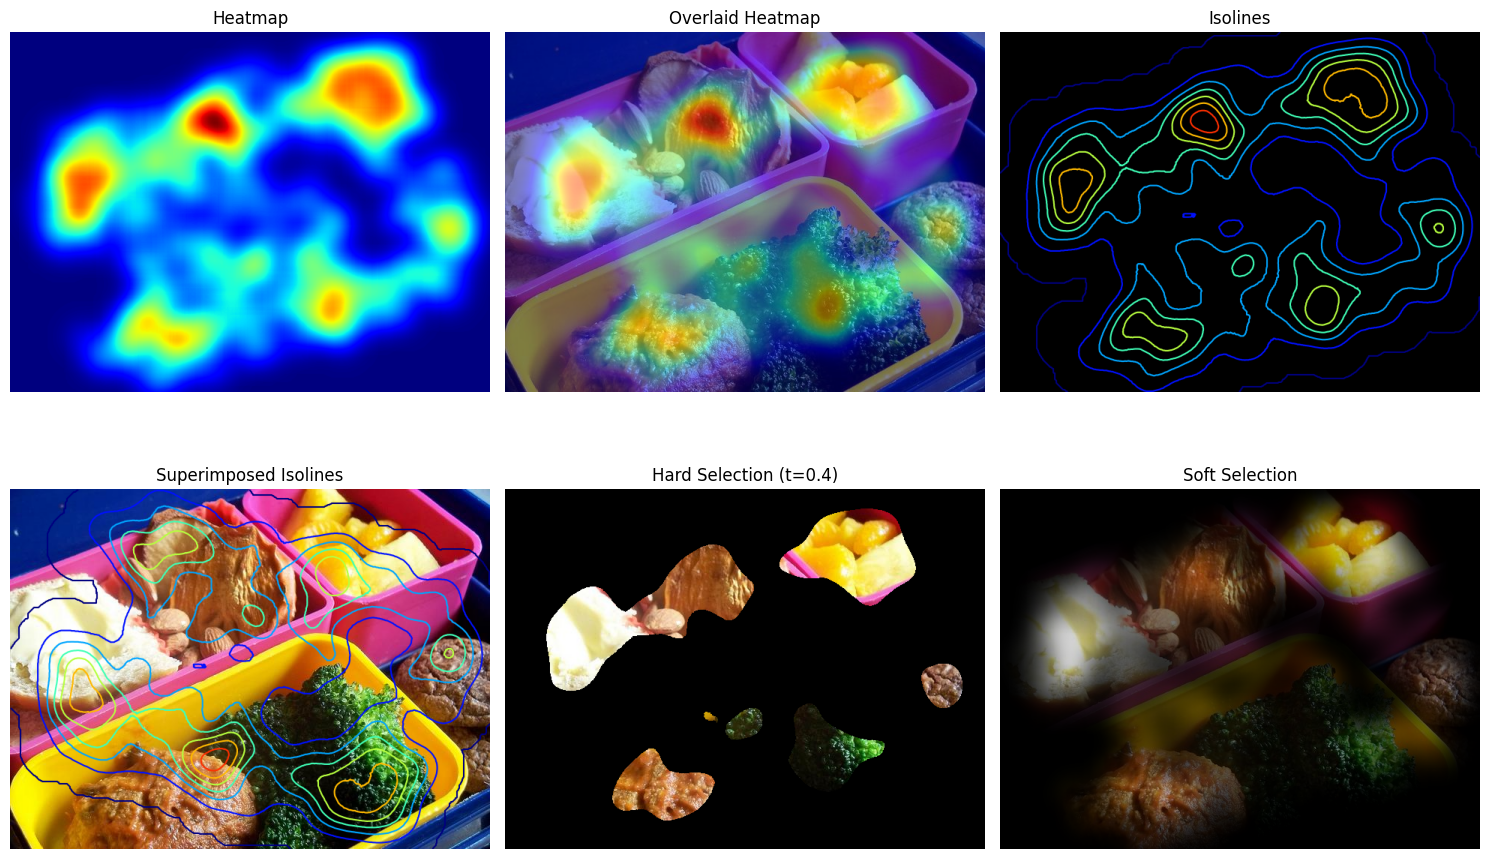

In [5]:
import io
import matplotlib.pyplot as plt
from PIL import Image
from typing import Union, Any
import math
import numpy as np
from pathlib import Path

Saliency = np.ndarray
RGBImage = Image.Image
Cmap = Any

def represent_heatmap(saliency: Saliency, cmap: Union[None, Cmap] = None) -> RGBImage:
    if cmap is None: # si pas de cmap fourni
        grayscale_array = (saliency * 255).astype(np.uint8) # commme les valeurs sont entre 0 et 1 on multiplie par 255 pour remplir les canaux de couleurs
        gray_img = Image.fromarray(grayscale_array, mode="L") #mode L pour niveau de gris
        return gray_img.convert("RGB") #on doit renvoyer une RGBImage obligatoirement
        
    else:
        rgba_array = cmap(saliency) 
        rgba_array = rgba_array[:, :, :3] # on garde toutes les lignes et colonnes RGB jusqu'a l'index 2, donc pas la transparence, juste RGB 
        rgb_scaled = rgba_array * 255 # pareil qu'au dessus on veut des valeurs entre 0 et 255
        final_array = rgb_scaled.astype(np.uint8) #pas de float
        heatmap_img = Image.fromarray(final_array, mode="RGB") 
        return heatmap_img 


def represent_heatmap_overlaid(saliency: Saliency, image: RGBImage, cmap: Union[None, Cmap] = None) -> RGBImage:
    #on réutilise notre heatmap au dessus
    heatmap = represent_heatmap(saliency, cmap)
    
    if heatmap.size != image.size: #on peut que fusionner des images de même taille, donc on vérifie 
        heatmap = heatmap.resize(image.size, Image.Resampling.LANCZOS)
    
    # dans le TD : Combine(Heat(x, y), Img(x,y)), fusion avec transparence à 50%
    return Image.blend(image, heatmap, alpha=0.5) 


def represent_isolines(saliency: Saliency, cmap: Union[None, Cmap] = None) -> RGBImage:
    height, width = saliency.shape 
    dpi = 100     # pour le graph
    fig, ax = plt.subplots(figsize=(width / dpi, height / dpi), dpi=dpi)     #figure et graphique avec les même dimensions que la matrice
    
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0) 
    ax.axis('off')     # pas d'axes
    fig.patch.set_facecolor('black') # arrière plan en noir
    
    if cmap is None:
        ax.contour(saliency, cmap='gray', origin='upper') # contours en ninveaux de gris, origin upper c'est pour dire que le point 0,0 est en haut à gauche
    else:
        ax.contour(saliency, cmap=cmap, origin='upper')         # contours en couleurs
        
    buf = io.BytesIO() 
    fig.savefig(buf, format='png', facecolor='black') 
    buf.seek(0) 
    plt.close(fig) 
    
    return Image.open(buf).convert("RGB") 


def represent_isolines_superimposed(saliency: Saliency, image: RGBImage, cmap: Union[None, Cmap] = None) -> RGBImage:
    width, height = image.size 
    dpi = 100
    fig, ax = plt.subplots(figsize=(width / dpi, height / dpi), dpi=dpi) 
    
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0) 
    ax.axis('off') 
    
    ax.imshow(image) #au lieu du fond noir on a directement l'image de base
    
    if cmap is None:
        ax.contour(saliency, cmap='gray', origin='upper') 
    else:
        ax.contour(saliency, cmap=cmap, origin='upper') 
        
    buf = io.BytesIO() 
    fig.savefig(buf, format='png') 
    buf.seek(0) 
    plt.close(fig) 
    
    return Image.open(buf).convert("RGB") 


def represent_hard_selection(saliency: Saliency, image: RGBImage, threshold: float) -> RGBImage:
    img_array = np.array(image.convert("RGB")) 
    
    mask = saliency >= threshold #si le pixel > threshold alors il vaut vrai, faux sinon
    
    mask_3d = np.stack([mask] * 3, axis=-1) #ligne généré par Gemini, si j'ai bien compris comme le masque est en 2D, il faut l'empiler 3 fois por en créer 3d qui s'applique au RGB
    
    # si le masque est Vrai, on garde la couleur de la photo, sinon on met en noir
    selected_array = np.where(mask_3d, img_array, 0).astype(np.uint8) 
    
    return Image.fromarray(selected_array, mode="RGB") 


def represent_soft_selection(saliency: Saliency, image: RGBImage, threshold: float) -> RGBImage:
    
    img_array = np.array(image.convert("RGB")).astype(np.float32) #gemini m'a dit que mettre les float éviter les erreurs lors des multiplicationsn
    
    sal_3d = np.stack([saliency] * 3, axis=-1) #ligne généré par Gemini, si j'ai bien compris comme le masque est en 2D, il faut l'empiler 3 fois por en créer 3d qui s'applique au RGB
    
    #on multiplie chaque pixel de la photo par son poids
    soft_array = (img_array * sal_3d).astype(np.uint8) 

    return Image.fromarray(soft_array, mode="RGB")

r_resolution = 1200 / 325 
d_distance = 900 
alpha_radians = math.radians(2) 
sigma = r_resolution * d_distance * math.tan(alpha_radians)

def generate_partial_saliency_map(width, height, x_fix, y_fix, sigma_val):
    x_coords = np.arange(0, width, 1) 
    y_coords = np.arange(0, height, 1) 
    x_grid, y_grid = np.meshgrid(x_coords, y_coords) 
    x_term = ((x_grid - x_fix) ** 2) / (2 * (sigma_val ** 2))
    y_term = ((y_grid - y_fix) ** 2) / (2 * (sigma_val ** 2))
    return np.exp(-(x_term + y_term))

def generate_global_saliency_map(width, height, fixations, sigma_val):
    global_map = np.zeros((height, width)) 
    for x_fix, y_fix in fixations:
        global_map += generate_partial_saliency_map(width, height, x_fix, y_fix, sigma_val)
    max_val = np.max(global_map)
    if max_val > 0:
        global_map = global_map / max_val
    return global_map

original_image = Image.open("test.jpg").convert("RGB")

saliency_img = Image.open("test_saliency_img.png").convert("L")
saliency_map = np.array(saliency_img).astype(np.float32) / 255.0

cmap = plt.get_cmap("jet")
THRESHOLD = 0.4

img_heat = represent_heatmap(saliency_map, cmap)
img_heat_overlaid = represent_heatmap_overlaid(saliency_map, original_image, cmap)
img_iso = represent_isolines(saliency_map, cmap)
img_iso_overlaid = represent_isolines_superimposed(saliency_map, original_image, cmap)
img_hard = represent_hard_selection(saliency_map, original_image, THRESHOLD)
img_soft = represent_soft_selection(saliency_map, original_image, THRESHOLD)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(img_heat)
axes[0, 0].set_title("Heatmap")

axes[0, 1].imshow(img_heat_overlaid)
axes[0, 1].set_title("Overlaid Heatmap")

axes[0, 2].imshow(img_iso)
axes[0, 2].set_title("Isolines")

axes[1, 0].imshow(img_iso_overlaid)
axes[1, 0].set_title("Superimposed Isolines")

axes[1, 1].imshow(img_hard)
axes[1, 1].set_title(f"Hard Selection (t={THRESHOLD})")

axes[1, 2].imshow(img_soft)
axes[1, 2].set_title("Soft Selection")

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()